# Coarse dates: individuals whose only life dates are centuries or millennia

In [1]:
import sys
import tempfile

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
KNOWN_PRECISIONS = ['day', 'month', 'year', 'decade']  # dates precise to the year or the decade
COARSE_PRECISIONS = ['century', 'millennium']
GROUPS = {'coarse birth and death': BLUE, 'coarse birth only': GREEN, 'coarse death only': ORANGE}
CENTURY = 100  # years
FIRST_CENTURY = -8  # 8th century BC, first century in the figure
SEED = 42

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Birth and death dates from Wikidata only. A date is **coarse** when its only Wikidata values are centuries or millennia. Three groups have no precise life date at all:

- **coarse birth and death**: both dates coarse,
- **coarse birth only**: a coarse birth, no death,
- **coarse death only**: a coarse death, no birth.

An individual with one coarse date and the other precise is left out: notebook 01 estimates the coarse date from the precise one.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
people = con.sql('''
    WITH wikidata AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL) AS birth,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL) AS death
        FROM individual
    ),
    dates AS (
        SELECT qid,
               list_filter(birth, d -> list_contains($known, d.precision))[1].year AS birth_year,
               list_filter(birth, d -> list_contains($coarse, d.precision))[1] AS coarse_birth,
               list_filter(death, d -> list_contains($known, d.precision))[1].year AS death_year,
               list_filter(death, d -> list_contains($coarse, d.precision))[1] AS coarse_death
        FROM wikidata
    )
    SELECT qid,
           CASE WHEN birth_year IS NOT NULL THEN 'precise' WHEN coarse_birth IS NOT NULL THEN 'coarse' ELSE 'none' END AS birth,
           CASE WHEN death_year IS NOT NULL THEN 'precise' WHEN coarse_death IS NOT NULL THEN 'coarse' ELSE 'none' END AS death,
           coalesce(coarse_birth.year, coarse_death.year) AS year,
           coalesce(coarse_birth.precision, coarse_death.precision) AS precision
    FROM dates
    WHERE coarse_birth IS NOT NULL OR coarse_death IS NOT NULL
''', params={'known': KNOWN_PRECISIONS, 'coarse': COARSE_PRECISIONS}).pl()
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals with a coarse birth or death')

150,693 individuals with a coarse birth or death


In [3]:
coarse = people.with_columns(
    pl.when((pl.col('birth') == 'coarse') & (pl.col('death') == 'coarse')).then(pl.lit('coarse birth and death'))
    .when((pl.col('birth') == 'coarse') & (pl.col('death') == 'none')).then(pl.lit('coarse birth only'))
    .when((pl.col('birth') == 'none') & (pl.col('death') == 'coarse')).then(pl.lit('coarse death only'))
    .alias('group')
)
print(f'{coarse.height:,} → {coarse["group"].is_not_null().sum():,} after leaving out the {coarse["group"].is_null().sum():,} with a precise other date')
coarse = coarse.filter(pl.col('group').is_not_null())
coarse.sample(5, seed=SEED)

150,693 → 108,030 after leaving out the 42,663 with a precise other date


qid,birth,death,year,precision,group
str,str,str,i64,str,str
"""Q61482126""","""coarse""","""none""",1901,"""century""","""coarse birth only"""
"""Q21583291""","""coarse""","""none""",2000,"""century""","""coarse birth only"""
"""Q95673048""","""coarse""","""coarse""",2000,"""millennium""","""coarse birth and death"""
"""Q51090052""","""coarse""","""none""",1950,"""century""","""coarse birth only"""
"""Q61470185""","""coarse""","""none""",1901,"""century""","""coarse birth only"""


## How many individuals

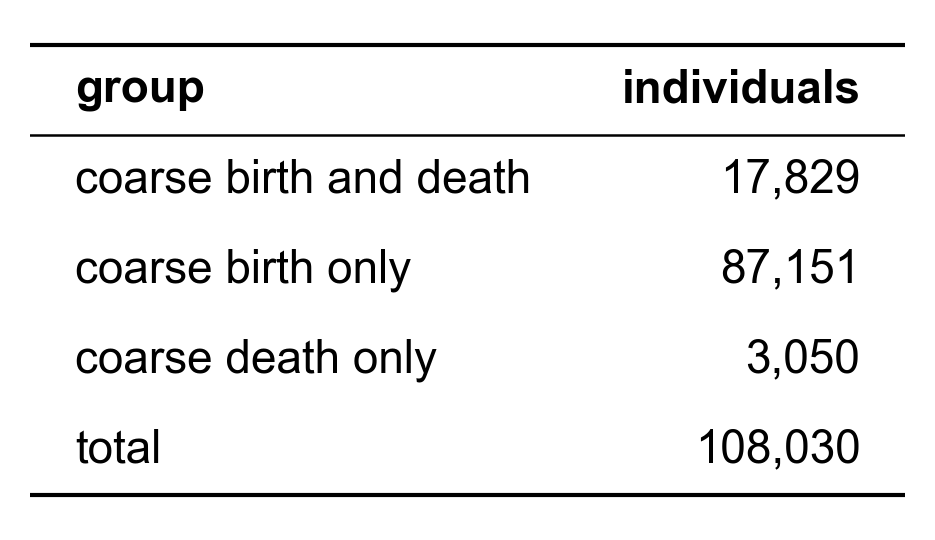

In [4]:
counts = coarse.group_by('group').len().sort(pl.col('group').replace_strict({g: i for i, g in enumerate(GROUPS)}))
show_table(pl.concat([counts, pl.DataFrame({'group': ['total'], 'len': [coarse.height]}, schema=counts.schema)])
           .select('group', pl.col('len').map_elements(lambda n: f'{n:,}', return_dtype=pl.String).alias('individuals')))

## Per century
An individual is placed in the century of the coarse birth, else of the coarse death. Wikidata stores a century as its last year (1600 = 1501–1600), its first year (1601 = 1601–1700) or its middle (1650): the century is the one that contains the stored year minus one, which reads the three the same way. Millennium dates are too coarse for a century and are left out of the figure.

In [5]:
def century_number(year):
    return pl.when(year > 0).then((year - 1) // CENTURY + 1).otherwise(-(((-year).clip(1) - 1) // CENTURY + 1))


def century_label(number):
    suffix = 'th' if 10 <= abs(number) % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(abs(number) % 10, 'th')
    return f'{abs(number)}{suffix}' + (' BC' if number < 0 else '')


centuries = coarse.filter(pl.col('precision') == 'century').with_columns(century_number(pl.col('year')).alias('century'))
print(f'{coarse.height:,} → {centuries.height:,} after leaving out the {coarse.height - centuries.height:,} millennium dates')
per_century = (
    centuries.group_by('century', 'group').len()
    .pivot(on='group', index='century', values='len')
    .fill_null(0)
    .select('century', *GROUPS)
    .with_columns(pl.sum_horizontal(*GROUPS).alias('total'))
    .sort('century')
)
assert per_century['total'].sum() == centuries.height
per_century.with_columns(pl.col('century').map_elements(century_label, return_dtype=pl.String))

108,030 → 105,442 after leaving out the 2,588 millennium dates


century,coarse birth and death,coarse birth only,coarse death only,total
str,u32,u32,u32,u32
"""73rd BC""",0,0,1,1
"""44th BC""",0,1,0,1
"""37th BC""",1,0,0,1
"""35th BC""",1,0,0,1
"""32nd BC""",0,2,0,2
"""31st BC""",2,0,1,3
"""30th BC""",5,1,0,6
"""29th BC""",6,3,0,9
"""28th BC""",15,4,5,24


### Figure 1: Individuals with only coarse date information, per century

104,419 of 105,442 from the 8th BC century on


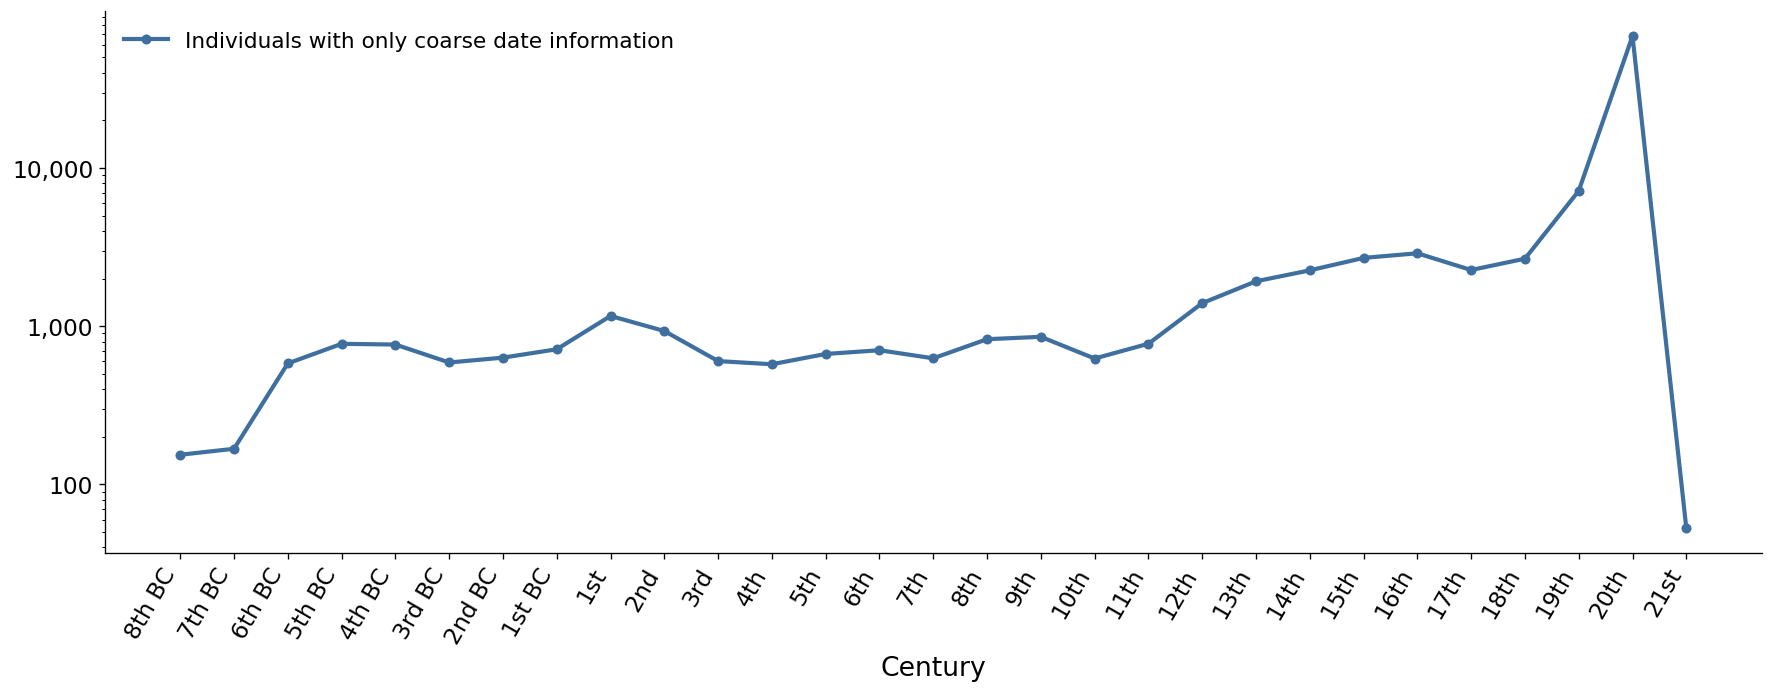

In [6]:
shown = per_century.filter(pl.col('century') >= FIRST_CENTURY)
print(f'{shown["total"].sum():,} of {per_century["total"].sum():,} from the {century_label(FIRST_CENTURY)} century on')
positions = list(range(shown.height))
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.plot(positions, shown['total'], color=MAIN_LINE_COLOR, linewidth=2.5, marker='o', markersize=5, label='Individuals with only coarse date information')
ax.set_yscale('log')
ax.set_xticks(positions)
ax.set_xticklabels([century_label(c) for c in shown['century']], rotation=60, ha='right', fontsize=14)
ax.set_xlabel('Century')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()